# Matplotlib for Data Analysts

A hands-on, practical guide to essential data visualization with **Matplotlib** and **Pandas**.

### Learning Objectives:
1. **Basic Line Plots**: Plotting coordinate pairs, customizing markers, colors, and grids.
2. **DataFrame Visualization**: Directly plotting Pandas columns and Series.
3. **Distribution Analysis**: Plotting **Histograms** to understand data spread and skewness.
4. **Outlier Detection**: Using **Box Plots** to spot extreme anomalies and cleaning them.
5. **Categorical Data**: Visualizing distributions using **Pie Charts** and **Bar Charts**.
6. **Bivariate Analysis**: Examining relationships between continuous variables with **Scatter Plots** and sorted trend lines.


In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Basic Line Plots
Visualizing basic coordinate pairs $(x, y)$ using `plt.plot()` and rendering with `plt.show()`.


In [5]:
x=[1,4,5]
y=[2,4,5]

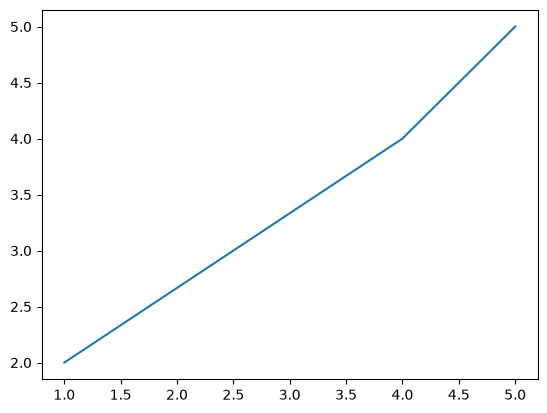

In [6]:
plt.plot(x,y)
plt.show()

## 2. Visualizing Pandas DataFrames
Plotting numerical columns directly from a DataFrame with custom line color (`color="red"`), star markers (`marker="*"`), and background grid lines (`plt.grid()`).


In [2]:
data ={
    "Salary":[200,400,500,300,600,450,988,345,876,567]
}

In [3]:
df =pd.DataFrame(data)
df

,Salary
0,200
1,400
2,500
3,300
4,600
5,450
6,988
7,345
8,876
9,567


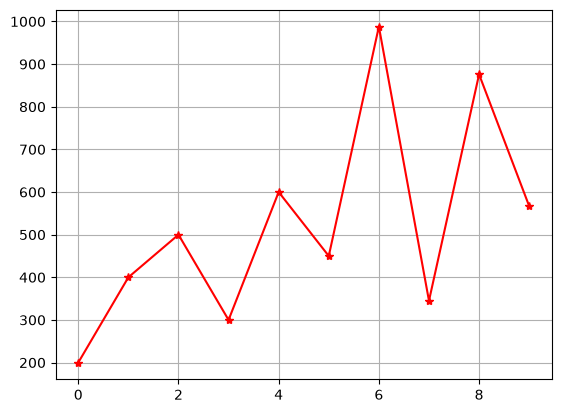

In [4]:
plt.plot(df["Salary"],color="red",marker="*")
plt.grid()
plt.show()

## 3. Frequency Distribution: Histograms
Histograms group numerical data into discrete bins (intervals) to display frequency distribution, spread, and modal clusters.


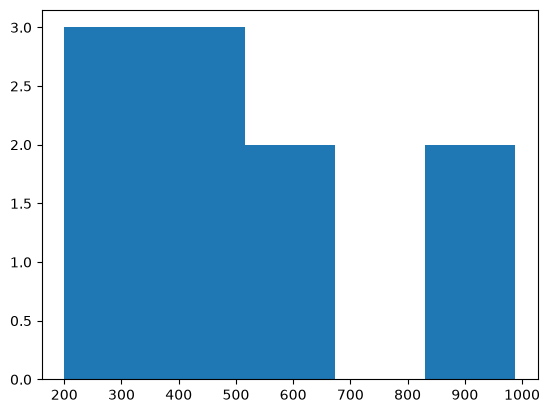

In [5]:
# histogram
plt.hist(df["Salary"],bins=5)
plt.show()

## 4. Outlier Detection with Box Plots
A Box Plot (box-and-whisker plot) summarizes numerical data using a 5-number summary (Min, Q1, Median, Q3, Max) and clearly flags potential outliers beyond the whiskers.


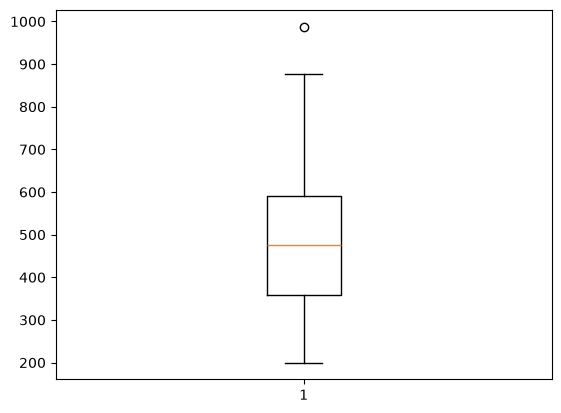

In [6]:
plt.boxplot(df['Salary'])
plt.show()

### Simulating an Outlier
Injecting an extreme salary value (`50,000`) into index 9 to observe how extreme values distort the scale of a box plot.


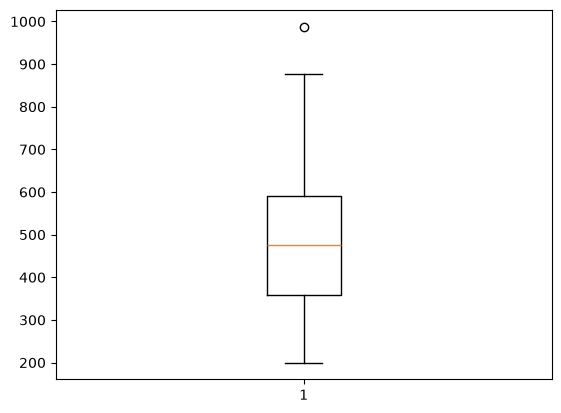

,Salary
0,200
1,400
2,500
3,300
4,600
5,450
6,988
7,345
8,876
9,567


In [7]:

plt.boxplot(df['Salary'])
plt.show()
df


### Cleaning & Dropping Outliers
Removing the outlier record to restore clean distribution for subsequent analyses.


In [44]:
df.drop(index=9,inplace=True)


/tmp/ipykernel_1992672/3102989791.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(index=9,inplace=True)


In [8]:
df

,Salary
0,200
1,400
2,500
3,300
4,600
5,450
6,988
7,345
8,876
9,567


## 5. Categorical Data Analysis
Adding department categories and aggregating counts with `value_counts()` to compare categorical representations.


In [9]:
df["Dept"]=["IT","Management","Law","Business","Marketing"]*2


In [55]:
df.head()

,Salary,Dept
0,200,IT
1,400,Management
2,500,Law
3,300,Business
4,600,Marketing


In [10]:
# count
count = df['Dept'].value_counts()
count

Dept
IT            2
Management    2
Law           2
Business      2
Marketing     2
Name: count, dtype: int64

### Visualizing Proportions: Pie Chart
Pie charts display percentage shares of each category using `autopct="%1.1f"`.


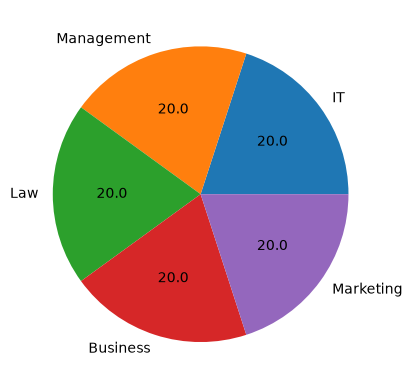

In [11]:
plt.pie(count,labels=count.index, autopct="%1.1f")
plt.show()

### Visualizing Counts: Bar Chart
Bar charts provide clearer side-by-side magnitude comparisons across categories.


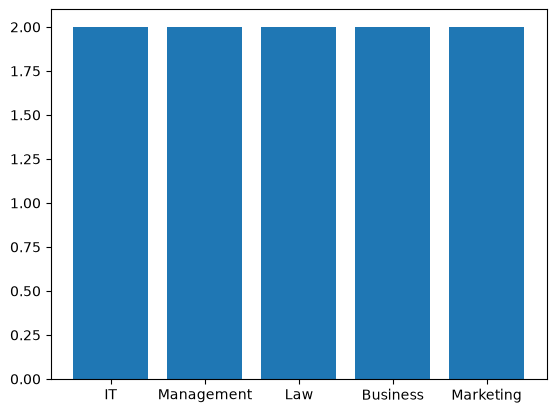

In [12]:
# counter plot

plt.bar(count.index,count)
plt.show()

## 6. Bivariate Analysis & Correlation
Comparing two numerical variables (`Age` vs `Salary`) to uncover patterns, trends, or relationships.


In [13]:
df['Age']=[32,45,65,76,34,56,78,98,12,24]

In [14]:
df

,Salary,Dept,Age
0,200,IT,32
1,400,Management,45
2,500,Law,65
3,300,Business,76
4,600,Marketing,34
5,450,IT,56
6,988,Management,78
7,345,Law,98
8,876,Business,12
9,567,Marketing,24


### Scatter Plot: Age vs Salary
Plotting points along the $(x, y)$ coordinate plane to observe point clustering or dispersion.


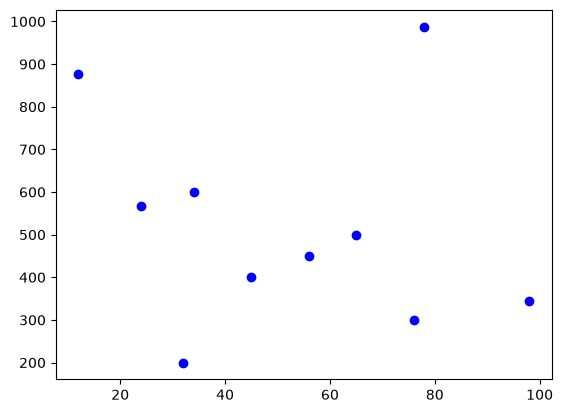

In [15]:
# scatter plot
plt.scatter(df['Age'],df['Salary'],color="blue")
plt.show()

### Sorted Trend Line
Sorting by `Age` before plotting avoids erratic crisscrossing lines and clearly highlights trends across values.


In [16]:
sort_age=df.sort_values("Age")


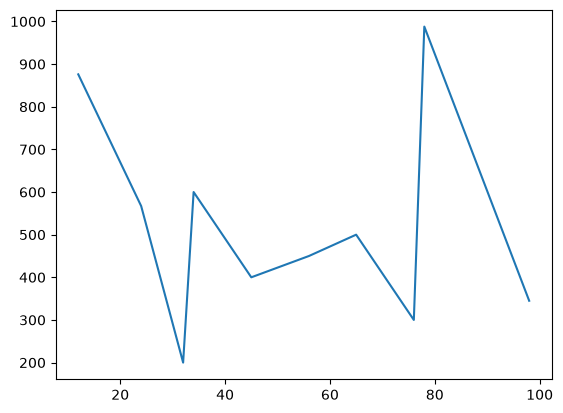

In [17]:
# line graph
plt.plot(sort_age['Age'],sort_age['Salary'])
plt.show()


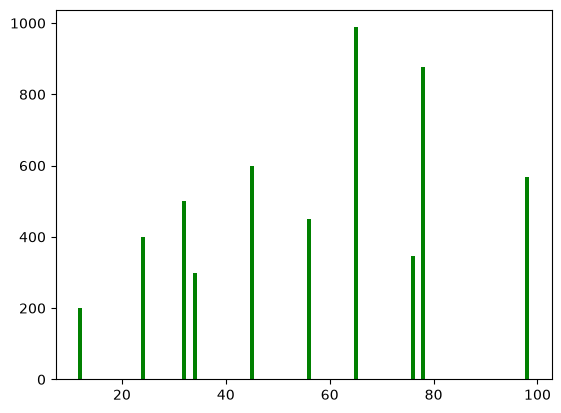

In [18]:
# bar chart

plt.bar(sort_age["Age"],df['Salary'],color="green")
plt.show()

In [20]:
# Numerical and categorical
It_dep = df[df['Dept']=="IT"] [ "Salary"]
It_dep

0    200
5    450
Name: Salary, dtype: int64

In [22]:
man_dep = df[df['Dept']=="Management"] [ "Salary"]
man_dep

1    400
6    988
Name: Salary, dtype: int64

In [23]:
law_dep = df[df['Dept']=="Law"] [ "Salary"]
law_dep

2    500
7    345
Name: Salary, dtype: int64

In [24]:
bus_dep = df[df['Dept']=="Business"] [ "Salary"]
bus_dep

3    300
8    876
Name: Salary, dtype: int64

In [25]:
mar_dep = df[df['Dept']=="Marketing"] [ "Salary"]
mar_dep

4    600
9    567
Name: Salary, dtype: int64

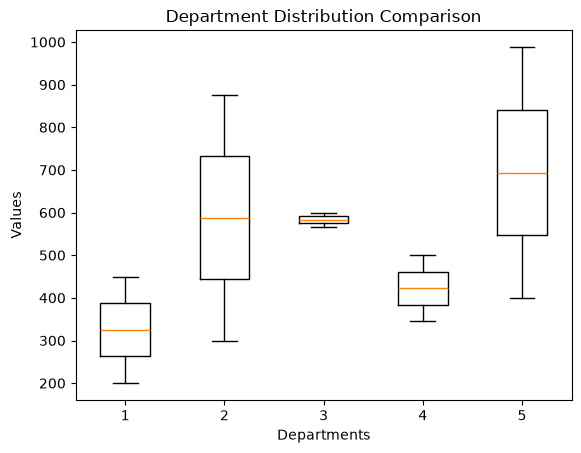

In [36]:
# box plot

plt.boxplot([It_dep,bus_dep,mar_dep,law_dep,man_dep],label=["It","Business","Marketing","Law","Management"])

plt.title("Department Distribution Comparison")
plt.xlabel("Departments")
plt.ylabel("Values")
plt.show()

In [37]:
salary_by_dept=df.groupby("Dept")['Salary'].sum()
salary_by_dept

Dept
Business      1176
IT             650
Law            845
Management    1388
Marketing     1167
Name: Salary, dtype: int64

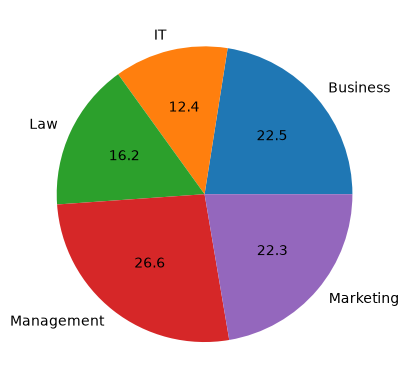

In [40]:
# piechart 
plt.pie(salary_by_dept,labels=salary_by_dept.index,autopct="%1.1f")
plt.show()

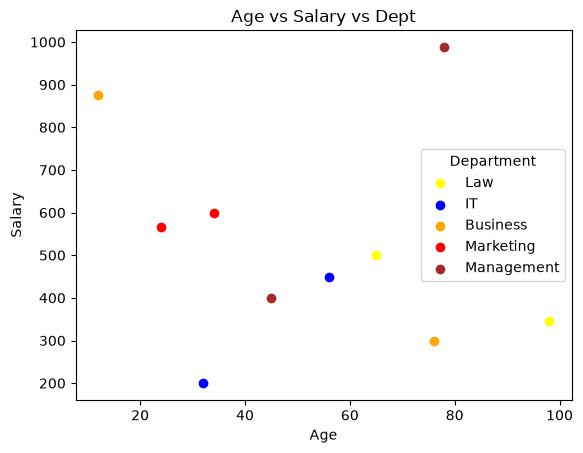

In [56]:
# 2 numeric and 1 category
colors = {
    "Law": "yellow",
    "IT": "blue",
    "Business": "orange",
    "Marketing":"Red",
    "Management":"Brown"
}

for dept, color in colors.items():
    data = df[df["Dept"] == dept]

    plt.scatter(
        data["Age"],
        data["Salary"],
        color=color,
        label=dept
    )

plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Age vs Salary vs Dept")
plt.legend(title="Department")
plt.show()